# ICD 341 - Advanced Statistical Computing: Labs 9-13
**Name:** BWALYA KASONGO  
**Student Number:** 202403418  
**Department of Mathematics and Statistics, Mulungushi University**  
**Due:** 30 October 2026, 23:59

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(341)     # fixed seed so results are reproducible

# Lab 1: Bootstrap and resampling

## Question 1. Bootstrap the mean of [3, 4, 5, 7, 8, 9] and report a 95% percentile interval
**Steps.** (1) Draw a sample of the same size n = 6 *with replacement* from the data. (2) Compute its mean. (3) Repeat B = 10,000 times. (4) The 2.5th and 97.5th percentiles of the bootstrap means form the 95% percentile interval.

Observed mean            : 6.0
Mean of bootstrap means  : 5.9933
Bootstrap standard error : 0.8767
95% percentile interval for the mean: (4.333, 7.667)


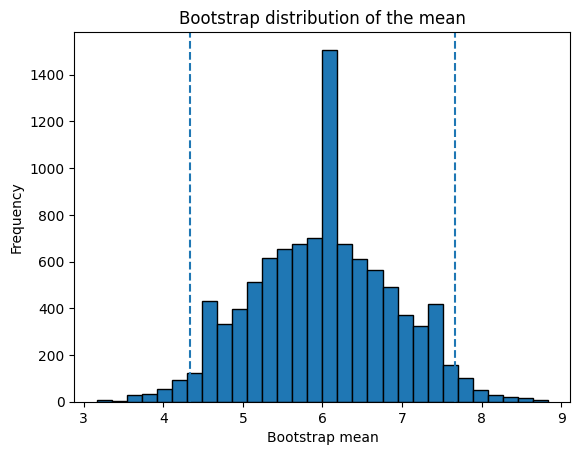

In [2]:
data = np.array([3, 4, 5, 7, 8, 9])
n = len(data)
B = 10_000

# each row is one bootstrap resample of size n; take the mean of every row
boot_means = rng.choice(data, size=(B, n), replace=True).mean(axis=1)

print("Observed mean            :", data.mean())
print("Mean of bootstrap means  :", boot_means.mean().round(4))
print("Bootstrap standard error :", boot_means.std(ddof=1).round(4))

lo, hi = np.percentile(boot_means, [2.5, 97.5])
print(f"95% percentile interval for the mean: ({lo:.3f}, {hi:.3f})")

plt.hist(boot_means, bins=30, edgecolor="black")
plt.axvline(lo, linestyle="--"); plt.axvline(hi, linestyle="--")
plt.xlabel("Bootstrap mean"); plt.ylabel("Frequency")
plt.title("Bootstrap distribution of the mean"); plt.show()

**Answer:** the observed mean is 6. The 95% percentile interval is about (4.3, 7.7). Your exact limits can differ slightly from run to run because resampling is random.

## Question 2. Bootstrap the median of the same data
The method is identical, but the statistic computed on each resample is the median. (The observed median is (5 + 7)/2 = 6.)

Observed median            : 6.0
Mean of bootstrap medians  : 6.0102
Bootstrap standard error   : 1.3849
95% percentile interval for the median: (3.500, 8.500)


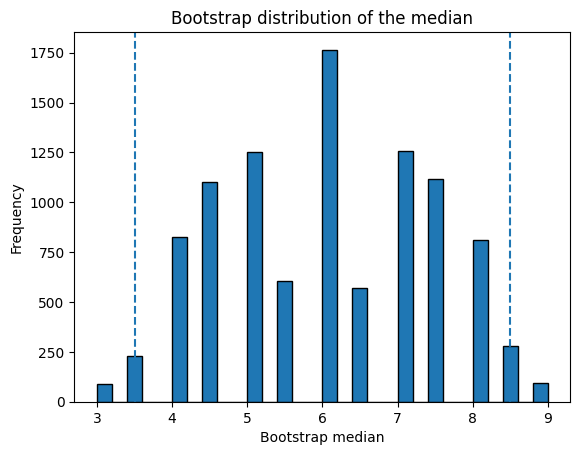

In [3]:
boot_medians = np.median(rng.choice(data, size=(B, n), replace=True), axis=1)

print("Observed median            :", np.median(data))
print("Mean of bootstrap medians  :", boot_medians.mean().round(4))
print("Bootstrap standard error   :", boot_medians.std(ddof=1).round(4))

lo_m, hi_m = np.percentile(boot_medians, [2.5, 97.5])
print(f"95% percentile interval for the median: ({lo_m:.3f}, {hi_m:.3f})")

plt.hist(boot_medians, bins=30, edgecolor="black")
plt.axvline(lo_m, linestyle="--"); plt.axvline(hi_m, linestyle="--")
plt.xlabel("Bootstrap median"); plt.ylabel("Frequency")
plt.title("Bootstrap distribution of the median"); plt.show()

**Answer:** the interval for the median is wider and lumpier than for the mean. The median can only take values that are data points or midpoints between them, so the bootstrap distribution is discrete.

## Question 3. Simulate a parametric bootstrap from a fitted normal model
**Steps.** (1) Fit a normal model to the data by estimating mu and sigma. (2) Simulate B new datasets of size n from N(mu_hat, sigma_hat^2) instead of resampling the data. (3) Compute the statistic on each simulated dataset. (4) Take percentiles.

In [4]:
mu_hat = data.mean()
sigma_hat = data.std(ddof=1)
print(f"Fitted normal model: mu_hat = {mu_hat:.4f}, sigma_hat = {sigma_hat:.4f}")

B = 10_000
sims = rng.normal(loc=mu_hat, scale=sigma_hat, size=(B, n))   # B simulated datasets of size n

pb_means = sims.mean(axis=1)
pb_medians = np.median(sims, axis=1)

for name, vals in [("mean", pb_means), ("median", pb_medians)]:
    lo, hi = np.percentile(vals, [2.5, 97.5])
    print(f"Parametric bootstrap {name:6s}: SE = {vals.std(ddof=1):.4f}, 95% interval = ({lo:.3f}, {hi:.3f})")

# Compare with the theoretical standard error of the mean: sigma / sqrt(n)
print("Theoretical SE of the mean:", round(sigma_hat / np.sqrt(n), 4))

Fitted normal model: mu_hat = 6.0000, sigma_hat = 2.3664
Parametric bootstrap mean  : SE = 0.9695, 95% interval = (4.082, 7.844)
Parametric bootstrap median: SE = 1.0980, 95% interval = (3.817, 8.124)
Theoretical SE of the mean: 0.9661


**Interpretation:** the parametric bootstrap relies on the normal model being a good description of the data. Its standard error for the mean matches the theoretical value sigma/sqrt(n), and it gives a smoother distribution than the non-parametric bootstrap on such a tiny sample.

## Question 4. Explain one way data leakage can occur during model validation
**Explanation.** Data leakage happens when information from the validation or test data influences the training of the model, so the validation score is too optimistic and the model performs worse on truly new data.

**Example: preprocessing before splitting.** If you standardise features, impute missing values, or select the "best" features using the *whole* dataset and only afterwards split into training and test sets (or cross-validation folds), the test observations have already contributed to the mean, standard deviation or feature choice. The model has therefore "seen" the test data indirectly. The correct approach is to do every data-dependent step *inside* each training fold, for example by using a scikit-learn `Pipeline`.

Other forms of leakage include duplicated rows or the same patient/household appearing in both training and test sets, and using features that contain the outcome or are only known after the outcome (target leakage).

The demonstration below uses 2000 pure-noise features and random labels, so the true accuracy is 50%.

In [5]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

Xn = rng.standard_normal((100, 2000))        # 100 observations, 2000 noise features
yn = rng.integers(0, 2, size=100)            # random labels: there is no real signal

# WRONG (leaky): choose the 20 best features using ALL the data, then cross-validate
X_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, yn, cv=5).mean()

# RIGHT: feature selection happens inside each training fold through a Pipeline
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(pipe, Xn, yn, cv=5).mean()

print(f"Leaky CV accuracy  : {leaky:.3f}   (looks good, but is an illusion)")
print(f"Correct CV accuracy: {honest:.3f}   (close to 0.5, the truth for random labels)")

Leaky CV accuracy  : 0.880   (looks good, but is an illusion)
Correct CV accuracy: 0.440   (close to 0.5, the truth for random labels)


# Lab 2: Bayesian MCMC

## Question 1. Implement random-walk Metropolis-Hastings (MH) for a standard normal target
**Steps.** (1) Start at x0. (2) Propose y = x + Normal(0, step^2). (3) Compute the acceptance ratio. With a symmetric proposal it is pi(y)/pi(x), and for N(0,1) the log of the unnormalised density is -x^2/2. (4) Accept y with probability min(1, ratio), otherwise stay at x. (5) Repeat, then discard an initial burn-in.

Acceptance rate: 0.446
Mean after burn-in: 0.0001  (target 0)
SD after burn-in  : 1.0006  (target 1)


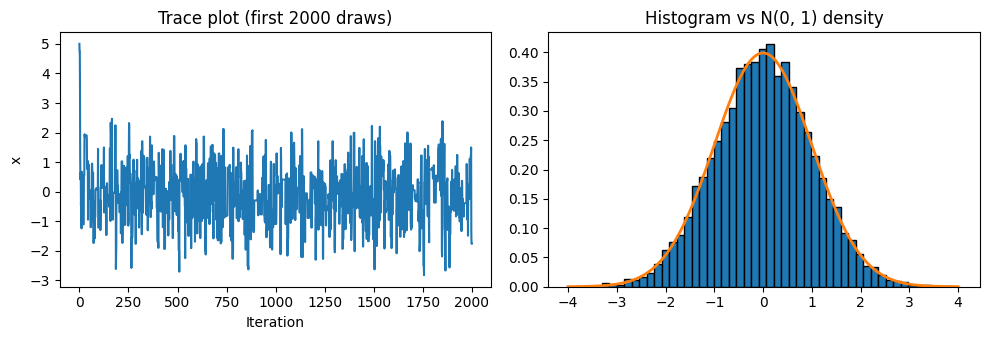

step =   0.1: acceptance rate = 0.963, sample SD = 1.260
step =   2.4: acceptance rate = 0.446, sample SD = 1.029
step =  20.0: acceptance rate = 0.060, sample SD = 0.983


In [6]:
def log_target(x):
    return -0.5 * x ** 2          # log of the unnormalised N(0, 1) density

def metropolis_hastings(n_samples, step=2.4, x0=0.0, rng=rng):
    samples = np.empty(n_samples)
    x = x0
    accepted = 0
    for i in range(n_samples):
        proposal = x + rng.normal(0.0, step)               # random-walk proposal
        log_alpha = log_target(proposal) - log_target(x)   # log acceptance ratio
        if np.log(rng.uniform()) < log_alpha:              # accept with prob min(1, ratio)
            x = proposal
            accepted += 1
        samples[i] = x
    return samples, accepted / n_samples

samples, acc_rate = metropolis_hastings(20_000, step=2.4, x0=5.0)   # deliberately bad start at 5
burn = 2_000
post = samples[burn:]

print(f"Acceptance rate: {acc_rate:.3f}")
print(f"Mean after burn-in: {post.mean():.4f}  (target 0)")
print(f"SD after burn-in  : {post.std(ddof=1):.4f}  (target 1)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(samples[:2000]); ax[0].set_title("Trace plot (first 2000 draws)")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("x")
ax[1].hist(post, bins=50, density=True, edgecolor="black")
grid = np.linspace(-4, 4, 200)
ax[1].plot(grid, stats.norm.pdf(grid), linewidth=2)
ax[1].set_title("Histogram vs N(0, 1) density"); plt.tight_layout(); plt.show()

# Effect of the proposal step size
for s in [0.1, 2.4, 20]:
    sm, a = metropolis_hastings(10_000, step=s, x0=0.0)
    print(f"step = {s:5.1f}: acceptance rate = {a:.3f}, sample SD = {sm.std(ddof=1):.3f}")

**Answer:** the chain moves quickly from the bad start at 5 into the high-probability region. After burn-in the mean is near 0 and the standard deviation near 1. A very small step gives a high acceptance rate but slow exploration; a very large step gives a very low acceptance rate; a moderate step (about 2.4 here, acceptance about 40 to 50%) works best.

## Question 2. Estimate a Bernoulli probability with a Beta(2, 2) prior after 8 successes in 12 trials
**Steps.** The Beta prior is conjugate to the Bernoulli/binomial likelihood, so the posterior is Beta(a + successes, b + failures) = Beta(2 + 8, 2 + 4) = **Beta(10, 6)**. Its mean is 10/16 = 0.625. We verify this with MCMC as well.

Posterior: Beta(10, 6)
Posterior mean   : 0.6250
Posterior mode   : 0.6429
Posterior SD     : 0.1174
95% credible interval: (0.3838, 0.8366)
Sample proportion (MLE): 0.6667


MCMC posterior mean: 0.6261,  MCMC 95% interval: (0.3913, 0.8356)


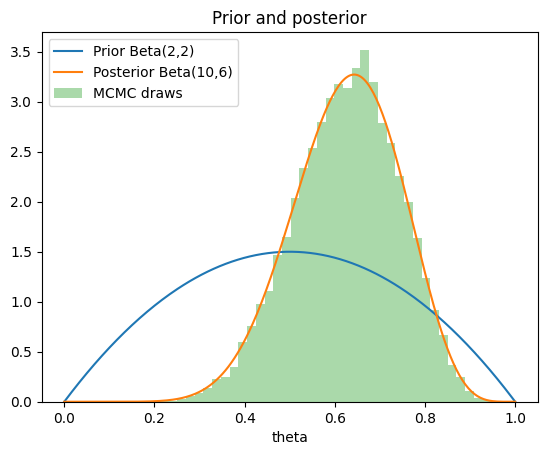

In [7]:
a0, b0 = 2, 2
successes, trials = 8, 12
failures = trials - successes

a_post, b_post = a0 + successes, b0 + failures
posterior = stats.beta(a_post, b_post)

print(f"Posterior: Beta({a_post}, {b_post})")
print(f"Posterior mean   : {posterior.mean():.4f}")
print(f"Posterior mode   : {(a_post - 1) / (a_post + b_post - 2):.4f}")
print(f"Posterior SD     : {posterior.std():.4f}")
ci = posterior.interval(0.95)
print(f"95% credible interval: ({ci[0]:.4f}, {ci[1]:.4f})")
print(f"Sample proportion (MLE): {successes / trials:.4f}")

# ---- Check with random-walk Metropolis-Hastings on theta ----
def log_post(theta):
    if theta <= 0 or theta >= 1:
        return -np.inf
    return (a0 - 1 + successes) * np.log(theta) + (b0 - 1 + failures) * np.log(1 - theta)

theta = 0.5
draws = np.empty(30_000)
for i in range(len(draws)):
    prop = theta + rng.normal(0, 0.2)
    if np.log(rng.uniform()) < log_post(prop) - log_post(theta):
        theta = prop
    draws[i] = theta
draws = draws[3_000:]
print(f"MCMC posterior mean: {draws.mean():.4f},  MCMC 95% interval: "
      f"({np.percentile(draws, 2.5):.4f}, {np.percentile(draws, 97.5):.4f})")

grid = np.linspace(0, 1, 300)
plt.plot(grid, stats.beta(a0, b0).pdf(grid), label="Prior Beta(2,2)")
plt.plot(grid, posterior.pdf(grid), label="Posterior Beta(10,6)")
plt.hist(draws, bins=40, density=True, alpha=0.4, label="MCMC draws")
plt.xlabel("theta"); plt.legend(); plt.title("Prior and posterior"); plt.show()

**Answer:** the posterior is Beta(10, 6) with mean 0.625 and a 95% credible interval of about (0.38, 0.84). The posterior mean (0.625) lies between the prior mean (0.5) and the sample proportion (0.667), because the prior pulls the estimate slightly towards 0.5.

## Question 3. Explain trace plots, ACF, R-hat and ESS
- **Trace plot:** a plot of the sampled values against the iteration number. A well-behaved chain looks like a "fuzzy caterpillar" that fluctuates around a constant level with no trends or long flat stretches. Several chains started from different places should overlap. Trends mean the chain has not converged (burn-in too short); long stuck stretches mean poor mixing.
- **ACF (autocorrelation function):** the correlation between the chain and a copy of itself shifted by a lag k. MCMC draws are dependent. If the ACF decays quickly to zero the draws are almost independent; a slow decay means strongly correlated draws and less information per sample.
- **R-hat (Gelman-Rubin statistic):** compares the variance *between* several chains with the variance *within* chains. If all chains have converged to the same distribution, R-hat is close to 1. Values above about 1.01 (older rule of thumb: 1.1) indicate that the chains have not converged or mixed.
- **ESS (effective sample size):** the number of independent draws that would carry the same information as the correlated MCMC draws: ESS = N / (1 + 2 x sum of autocorrelations). A small ESS relative to N means high autocorrelation. A common guideline is an ESS of at least a few hundred (often 400 or more across chains) for reliable summaries.

The code below computes each of these for four chains started from different values.

R-hat : 1.0000  (should be close to 1)
ESS per chain: [1178, 910, 1083, 1041] out of 4500 draws


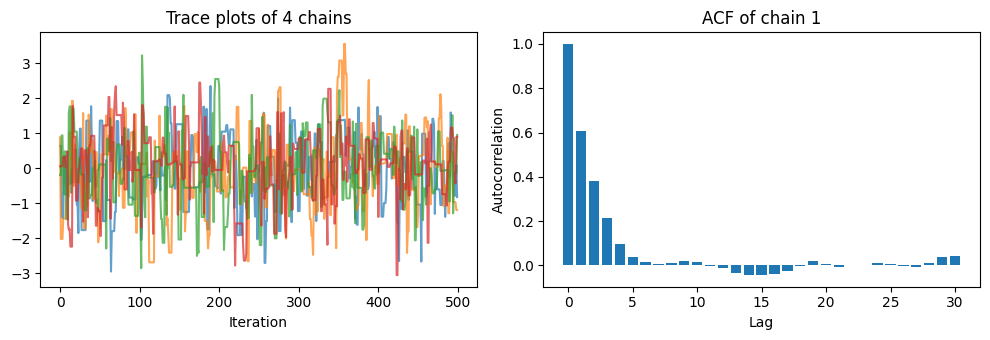

In [8]:
def acf(x, max_lag=50):
    x = x - x.mean()
    n = len(x)
    var = np.dot(x, x) / n
    return np.array([np.dot(x[:n - k], x[k:]) / (n * var) for k in range(max_lag + 1)])

def ess(x, max_lag=200):
    rho = acf(x, max_lag)
    s = 0.0
    for k in range(1, len(rho)):
        if rho[k] < 0:          # stop at the first negative autocorrelation
            break
        s += rho[k]
    return len(x) / (1 + 2 * s)

def rhat(chains):               # chains has shape (m chains, n draws)
    m, n = chains.shape
    W = chains.var(axis=1, ddof=1).mean()                 # within-chain variance
    Bv = n * chains.mean(axis=1).var(ddof=1)              # between-chain variance
    var_hat = (n - 1) / n * W + Bv / n
    return np.sqrt(var_hat / W)

starts = [-10, -3, 3, 10]
chains = np.array([metropolis_hastings(5_000, step=2.4, x0=s)[0][500:] for s in starts])

print(f"R-hat : {rhat(chains):.4f}  (should be close to 1)")
print("ESS per chain:", [int(round(ess(c))) for c in chains], "out of", chains.shape[1], "draws")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for c in chains:
    ax[0].plot(c[:500], alpha=0.7)
ax[0].set_title("Trace plots of 4 chains"); ax[0].set_xlabel("Iteration")
ax[1].bar(range(31), acf(chains[0], 30))
ax[1].set_title("ACF of chain 1"); ax[1].set_xlabel("Lag"); ax[1].set_ylabel("Autocorrelation")
plt.tight_layout(); plt.show()

## Question 4. Write a PyMC model for normally distributed observations
**Model:** y_i ~ Normal(mu, sigma), with weakly informative priors mu ~ Normal(0, 100) and sigma ~ HalfNormal(50). Install the libraries first with `pip install pymc arviz`.

In [9]:
import pymc as pm
import arviz as az

obs = rng.normal(loc=50, scale=10, size=100)      # simulated observations (true mu = 50, sigma = 10)

with pm.Model() as normal_model:
    mu = pm.Normal("mu", mu=0, sigma=100)               # prior for the mean
    sigma = pm.HalfNormal("sigma", sigma=50)            # prior for the standard deviation (positive)
    y = pm.Normal("y", mu=mu, sigma=sigma, observed=obs)  # likelihood

    idata = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                      random_seed=341, progressbar=False)

print(az.summary(idata, var_names=["mu", "sigma"]))

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [mu, sigma]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 1 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


        mean    sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
mu     49.92  0.97       48       51     1633     1073  1.00     0.024   0.022
sigma   9.48  0.69      8.4       11     1817     1284  1.00     0.016   0.017


**Interpretation:** the posterior means of mu and sigma are close to 50 and 10. In the summary table, `r_hat` close to 1.00 and large `ess_bulk` and `ess_tail` values show that sampling worked. Use `az.plot_trace(idata)` to see the trace plots. (Your numbers will differ slightly.)

# Lab 3: Advanced simulation

## Question 1. Generate 5,000 exponential samples using inverse transform with rate 3
**Steps.** The CDF of an exponential with rate lambda is F(x) = 1 - exp(-lambda x). Solving u = F(x) gives the inverse **x = -ln(1 - u) / lambda**. If U ~ Uniform(0, 1), then X = F^-1(U) has the exponential distribution.

Sample mean     : 0.3304   (theory 1/rate = 0.3333)
Sample variance : 0.1146   (theory 1/rate^2 = 0.1111)
Kolmogorov-Smirnov test vs Exp(3): statistic = 0.0153, p-value = 0.1907


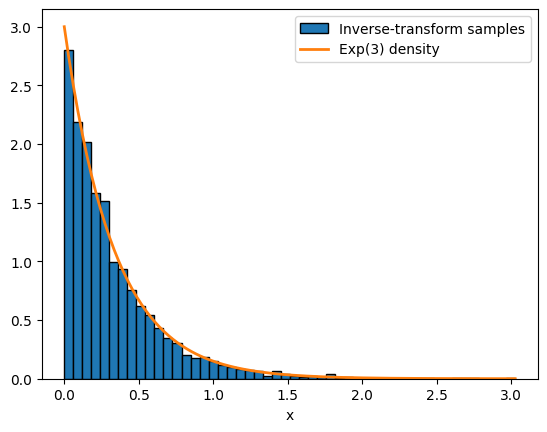

In [10]:
rate = 3
u = rng.uniform(size=5000)
x = -np.log(1 - u) / rate

print(f"Sample mean     : {x.mean():.4f}   (theory 1/rate = {1/rate:.4f})")
print(f"Sample variance : {x.var(ddof=1):.4f}   (theory 1/rate^2 = {1/rate**2:.4f})")
ks = stats.kstest(x, "expon", args=(0, 1 / rate))
print(f"Kolmogorov-Smirnov test vs Exp(3): statistic = {ks.statistic:.4f}, p-value = {ks.pvalue:.4f}")

grid = np.linspace(0, x.max(), 200)
plt.hist(x, bins=50, density=True, edgecolor="black", label="Inverse-transform samples")
plt.plot(grid, rate * np.exp(-rate * grid), linewidth=2, label="Exp(3) density")
plt.legend(); plt.xlabel("x"); plt.show()

**Answer:** the sample mean is close to 1/3 and the variance close to 1/9. The large KS p-value shows no evidence against the exponential distribution.

## Question 2. Sample from a categorical distribution with probabilities [0.1, 0.6, 0.3]
**Steps.** Compute the cumulative probabilities [0.1, 0.7, 1.0]. Draw U ~ Uniform(0, 1) and return the first category whose cumulative probability is at least U.

In [11]:
p = np.array([0.1, 0.6, 0.3])
cum = np.cumsum(p)                      # [0.1, 0.7, 1.0]

u = rng.uniform(size=10_000)
draws = np.minimum(np.searchsorted(cum, u), len(p) - 1)    # category index 0, 1 or 2

freq = np.bincount(draws, minlength=3) / len(draws)
print("Cumulative probabilities:", cum)
print("Empirical frequencies   :", freq)
print("True probabilities      :", p)

# Built-in alternative
draws2 = rng.choice(3, size=10_000, p=p)
print("rng.choice frequencies  :", np.bincount(draws2, minlength=3) / 10_000)

Cumulative probabilities: [0.1 0.7 1. ]
Empirical frequencies   : [0.0968 0.5953 0.3079]
True probabilities      : [0.1 0.6 0.3]
rng.choice frequencies  : [0.1    0.5894 0.3106]


## Question 3. Implement rejection sampling for Beta(2, 2)
**Steps.** The target density is f(x) = 6x(1 - x) on (0, 1). Its maximum is f(0.5) = 1.5. Use the Uniform(0, 1) proposal g(x) = 1 and the constant M = 1.5, so that f(x) <= M g(x). Propose X ~ U(0, 1) and U ~ U(0, 1); accept X if U <= f(X) / (M g(X)) = 4X(1 - X). The theoretical acceptance rate is 1/M = 2/3.

Acceptance rate: 0.666   (theory 1/M = 0.667)
Sample mean: 0.4986   (theory 0.5)
Sample variance: 0.0503   (theory 0.05)
KS test vs Beta(2,2) p-value: 0.8124


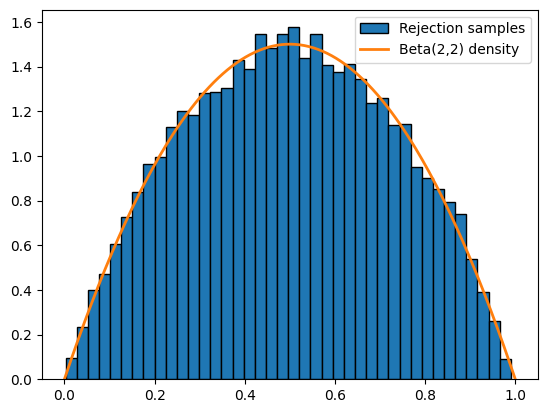

In [12]:
def beta22_pdf(x):
    return 6 * x * (1 - x)

M = 1.5     # f(x) <= M * g(x) with g(x) = 1 on (0, 1)

def rejection_sample_beta22(n, rng=rng):
    out = []
    tries = 0
    while len(out) < n:
        x = rng.uniform()                  # proposal from g
        u = rng.uniform()
        tries += 1
        if u <= beta22_pdf(x) / M:         # accept with probability f(x) / (M g(x))
            out.append(x)
    return np.array(out), n / tries

samples, acc = rejection_sample_beta22(10_000)
print(f"Acceptance rate: {acc:.3f}   (theory 1/M = {1/M:.3f})")
print(f"Sample mean: {samples.mean():.4f}   (theory 0.5)")
print(f"Sample variance: {samples.var(ddof=1):.4f}   (theory 0.05)")
print("KS test vs Beta(2,2) p-value:", round(stats.kstest(samples, "beta", args=(2, 2)).pvalue, 4))

grid = np.linspace(0, 1, 200)
plt.hist(samples, bins=40, density=True, edgecolor="black", label="Rejection samples")
plt.plot(grid, beta22_pdf(grid), linewidth=2, label="Beta(2,2) density")
plt.legend(); plt.show()

## Question 4. Describe the four main particle-filter steps
A particle filter (sequential Monte Carlo) tracks a hidden state x_t over time from noisy observations y_t using N weighted samples (particles).
1. **Initialise:** draw N particles from the prior distribution of the initial state and give them equal weights 1/N.
2. **Predict (propagate):** move every particle forward one time step using the state transition model, x_t^(i) ~ p(x_t | x_{t-1}^(i)), which adds process noise.
3. **Update (weight):** when the new observation y_t arrives, give each particle a weight proportional to its likelihood, w^(i) proportional to p(y_t | x_t^(i)), then normalise the weights so they sum to 1. The weighted average of the particles is the state estimate.
4. **Resample:** draw N new particles with replacement according to the weights (for example systematic resampling) and reset the weights to 1/N. This removes particles with negligible weight and copies the good ones, which prevents weight degeneracy. It is often done only when the effective sample size is low.

Steps 2 to 4 are repeated for each new observation. A small demonstration follows (random-walk state, noisy measurements).

RMSE of raw observations   : 0.914
RMSE of particle filter    : 0.560


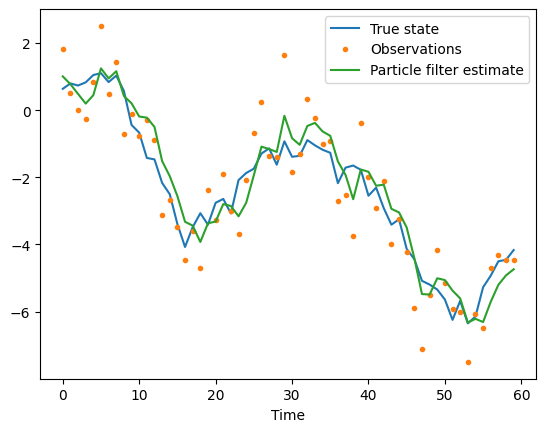

In [13]:
T, N = 60, 1000
q, r = 0.5, 1.0                                   # process and measurement noise SDs

# Simulate a hidden random walk and noisy observations
x_true = np.cumsum(rng.normal(0, q, T))
y_obs = x_true + rng.normal(0, r, T)

def systematic_resample(weights, rng):
    positions = (rng.uniform() + np.arange(len(weights))) / len(weights)
    return np.minimum(np.searchsorted(np.cumsum(weights), positions), len(weights) - 1)

particles = rng.normal(0, 1, N)                   # 1. Initialise
estimates = np.empty(T)
for t in range(T):
    particles = particles + rng.normal(0, q, N)               # 2. Predict
    w = stats.norm.pdf(y_obs[t], loc=particles, scale=r)      # 3. Update: likelihood weights
    w /= w.sum()                                              #    normalise
    estimates[t] = np.sum(w * particles)                      #    weighted state estimate
    particles = particles[systematic_resample(w, rng)]        # 4. Resample

print(f"RMSE of raw observations   : {np.sqrt(np.mean((y_obs - x_true)**2)):.3f}")
print(f"RMSE of particle filter    : {np.sqrt(np.mean((estimates - x_true)**2)):.3f}")

plt.plot(x_true, label="True state"); plt.plot(y_obs, ".", label="Observations")
plt.plot(estimates, label="Particle filter estimate")
plt.legend(); plt.xlabel("Time"); plt.show()

## Question 5. What a non-uniform SBC rank histogram may indicate
**Simulation-based calibration (SBC):** draw a parameter from the prior, simulate data from it, run the inference method, and record the *rank* of the true parameter among the posterior draws. If the model and the inference algorithm are correct, the ranks over many repetitions are **uniformly distributed**. A non-uniform histogram signals a problem:
- **U-shaped** (too many ranks at the extremes): the posterior is too narrow or overconfident, so the true value often falls in the tails.
- **Hump-shaped / inverse-U** (ranks concentrated in the middle): the posterior is too wide or underconfident.
- **Sloped or skewed** (more low ranks or more high ranks): the posterior is biased, so it systematically over- or under-estimates the parameter.
- **Spikes at the edges or irregular bars:** poor MCMC mixing and autocorrelated draws, or a bug in the model or sampler (for example the data generator and the fitted model do not match, or priors differ).

The demonstration below uses a conjugate normal model with a correct posterior and an artificially overconfident one.

Correct posterior   counts per bin: [104 112 112 108  98  86  96  81  79 124]
Overconfident (x0.5) counts per bin: [236  88  62  47  56  42  48  59  71 291]


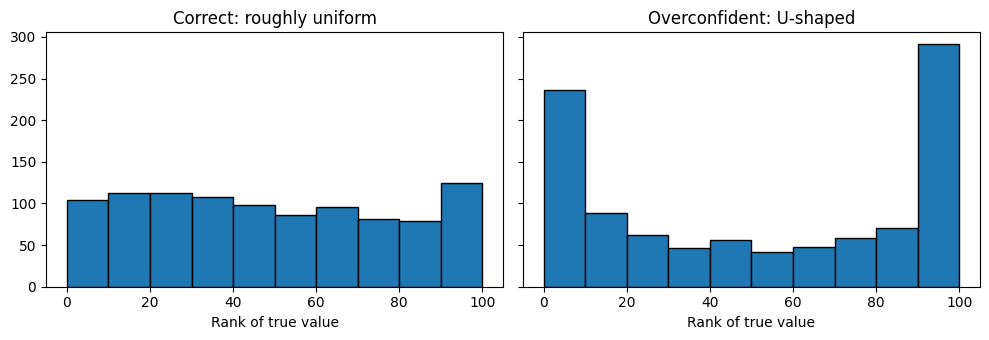

In [14]:
L, reps, n_obs = 100, 1000, 5                     # posterior draws, SBC repetitions, data size

def sbc_ranks(shrink):
    ranks = np.empty(reps, dtype=int)
    for i in range(reps):
        mu_true = rng.normal(0, 1)                     # draw from the prior N(0, 1)
        y = rng.normal(mu_true, 1, n_obs)              # simulate data
        post_mean = y.sum() / (n_obs + 1)              # exact posterior N(sum(y)/(n+1), 1/(n+1))
        post_sd = np.sqrt(1 / (n_obs + 1)) * shrink    # shrink < 1 makes the posterior too narrow
        draws = rng.normal(post_mean, post_sd, L)
        ranks[i] = np.sum(draws < mu_true)             # rank of the truth: 0, 1, ..., L
    return ranks

correct = sbc_ranks(1.0)
overconf = sbc_ranks(0.5)

bins = np.arange(0, L + 2, 10)
print("Correct posterior   counts per bin:", np.histogram(correct, bins=bins)[0])
print("Overconfident (x0.5) counts per bin:", np.histogram(overconf, bins=bins)[0])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
ax[0].hist(correct, bins=bins, edgecolor="black"); ax[0].set_title("Correct: roughly uniform")
ax[1].hist(overconf, bins=bins, edgecolor="black"); ax[1].set_title("Overconfident: U-shaped")
for a in ax: a.set_xlabel("Rank of true value")
plt.tight_layout(); plt.show()

# Lab 4: Testing, estimators and packaging

## Question 1. Write a function for the median and tests for a known result and empty input
**Steps.** (1) Put the function in a module file `stats_utils.py`. (2) Put the tests in `test_stats_utils.py`, where the file name must start with `test_`. (3) Run `pytest`. An empty input should raise a `ValueError`, and the test checks this with `pytest.raises`.

The next cell creates the module with the notebook command `%%writefile` (it must be the first line of the cell).

In [15]:
%%writefile stats_utils.py
"""Small statistics helpers used for testing practice."""


def median(values):
    """Return the median of a non-empty sequence of numbers."""
    data = sorted(values)
    n = len(data)
    if n == 0:
        raise ValueError("median() requires a non-empty input")
    mid = n // 2
    if n % 2 == 1:
        return data[mid]
    return (data[mid - 1] + data[mid]) / 2


def sample_proportion(successes, trials):
    """Estimate a probability as successes / trials."""
    if trials <= 0:
        raise ValueError("trials must be positive")
    if successes < 0 or successes > trials:
        raise ValueError("successes must be between 0 and trials")
    return successes / trials


def posterior_mean(successes, trials, a=2.0, b=2.0):
    """Posterior mean of a Bernoulli probability under a Beta(a, b) prior."""
    if trials < 0 or successes < 0 or successes > trials:
        raise ValueError("need 0 <= successes <= trials")
    return (a + successes) / (a + b + trials)

Writing stats_utils.py


In [16]:
%%writefile test_stats_utils.py
import pytest
from stats_utils import median


def test_median_known_result_even_length():
    assert median([3, 4, 5, 7, 8, 9]) == 6          # (5 + 7) / 2


def test_median_known_result_odd_length():
    assert median([7, 1, 3]) == 3                    # also checks that unsorted input works


def test_median_single_value():
    assert median([42]) == 42


def test_median_empty_input_raises():
    with pytest.raises(ValueError):
        median([])

Writing test_stats_utils.py


In [17]:
!python -m pytest test_stats_utils.py -v --color=no

============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-9.2.0, pluggy-1.7.0 -- /usr/bin/python
cachedir: .pytest_cache
rootdir: /home/claude/labs9_13
collecting ... 
collected 4 items                                                              

test_stats_utils.py::test_median_known_result_even_length 

PASSED         [ 25%]
test_stats_utils.py::test_median_known_result_odd_length PASSED          [ 50%]
test_stats_utils.py::test_median_single_value PASSED                     [ 75%]
test_stats_utils.py::test_median_empty_input_raises PASSED               [100%]

============================== 4 passed in 0.02s ===============================


**Answer:** all four tests pass. They check two known results (even and odd length), the single-value case, and that an empty input raises a `ValueError`.

## Question 2. Write tests that a probability estimate lies in [0, 1]
**Steps.** Test the estimator across many valid inputs, including the edge cases 0 successes and all successes, using `pytest.mark.parametrize`. Also test a Monte Carlo estimate with a fixed seed, and test that invalid inputs are rejected.

In [18]:
%%writefile test_probability.py
import numpy as np
import pytest
from stats_utils import sample_proportion, posterior_mean


@pytest.mark.parametrize("successes, trials", [(0, 10), (3, 10), (10, 10), (8, 12), (1, 1)])
def test_sample_proportion_in_unit_interval(successes, trials):
    p = sample_proportion(successes, trials)
    assert 0.0 <= p <= 1.0


@pytest.mark.parametrize("successes, trials", [(0, 0), (0, 10), (8, 12), (12, 12)])
def test_posterior_mean_in_unit_interval(successes, trials):
    p = posterior_mean(successes, trials, a=2, b=2)
    assert 0.0 <= p <= 1.0


def test_posterior_mean_known_value():
    assert posterior_mean(8, 12, a=2, b=2) == pytest.approx(10 / 16)


def test_monte_carlo_probability_in_unit_interval():
    rng = np.random.default_rng(0)
    p_hat = np.mean(rng.standard_normal(100_000) > 1.96)    # estimate of P(Z > 1.96)
    assert 0.0 <= p_hat <= 1.0
    assert p_hat == pytest.approx(0.025, abs=0.003)


@pytest.mark.parametrize("successes, trials", [(-1, 10), (11, 10), (1, 0)])
def test_invalid_inputs_raise(successes, trials):
    with pytest.raises(ValueError):
        sample_proportion(successes, trials)

Writing test_probability.py


In [19]:
!python -m pytest test_probability.py -v --color=no

============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-9.2.0, pluggy-1.7.0 -- /usr/bin/python
cachedir: .pytest_cache
rootdir: /home/claude/labs9_13
collecting ... 


collected 14 items                                                             

test_probability.py::test_sample_proportion_in_unit_interval[0-10] PASSED [  7%]
test_probability.py::test_sample_proportion_in_unit_interval[3-10] PASSED [ 14%]
test_probability.py::test_sample_proportion_in_unit_interval[10-10] PASSED [ 21%]
test_probability.py::test_sample_proportion_in_unit_interval[8-12] PASSED [ 28%]
test_probability.py::test_sample_proportion_in_unit_interval[1-1] PASSED [ 35%]
test_probability.py::test_posterior_mean_in_unit_interval[0-0] PASSED    [ 42%]
test_probability.py::test_posterior_mean_in_unit_interval[0-10] PASSED   [ 50%]
test_probability.py::test_posterior_mean_in_unit_interval[8-12] PASSED   [ 57%]
test_probability.py::test_posterior_mean_in_unit_interval[12-12] PASSED  [ 64%]
test_probability.py::test_posterior_mean_known_value PASSED              [ 71%]
test_probability.py::test_monte_carlo_probability_in_unit_interval PASSED [ 78%]
test_probability.py::test_invali

## Question 3. Implement a transformer that scales each column by its standard deviation
**Steps.** A scikit-learn transformer inherits from `BaseEstimator` and `TransformerMixin`, learns its parameters in `fit` (the per-column standard deviations, stored with a trailing underscore such as `scale_`) and applies them in `transform`. `fit_transform` comes free from `TransformerMixin`. The transformer only divides by the standard deviation and does not centre the data. Constant columns (standard deviation 0) are left unscaled to avoid division by zero.

In [20]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class StdScaler(BaseEstimator, TransformerMixin):
    """Scale every column by its (sample) standard deviation."""

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.scale_ = X.std(axis=0, ddof=1)
        self.scale_[self.scale_ == 0] = 1.0        # avoid dividing by zero for constant columns
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self, "scale_")
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("X has a different number of columns than during fit")
        return X / self.scale_


X = np.array([[1, 10, 5],
              [2, 20, 5],
              [3, 30, 5]], dtype=float)           # third column is constant

scaler = StdScaler()
X_scaled = scaler.fit_transform(X)
print("Column standard deviations (scale_):", scaler.scale_)
print("Scaled data:\n", X_scaled)
print("Std of each scaled column:", X_scaled.std(axis=0, ddof=1))

assert np.allclose(X_scaled[:, :2].std(axis=0, ddof=1), 1.0)      # non-constant columns have SD 1
assert np.allclose(scaler.transform(X), X_scaled)
print("All checks passed")

Column standard deviations (scale_): [ 1. 10.  1.]
Scaled data:
 [[1. 1. 5.]
 [2. 2. 5.]
 [3. 3. 5.]]
Std of each scaled column: [1. 1. 0.]
All checks passed


## Question 4. Create a minimal pyproject.toml and explain editable installation
**Steps.** Use the standard "src layout": a project folder containing `pyproject.toml` and `src/mystats/__init__.py`. The cell below creates this layout from Python.

In [21]:
from pathlib import Path

root = Path("mystats_project")
pkg = root / "src" / "mystats"
pkg.mkdir(parents=True, exist_ok=True)

(root / "pyproject.toml").write_text('''[build-system]
requires = ["setuptools>=61"]
build-backend = "setuptools.build_meta"

[project]
name = "mystats"
version = "0.1.0"
description = "Small statistics helpers"
requires-python = ">=3.9"
dependencies = ["numpy"]

[tool.setuptools.packages.find]
where = ["src"]
''')

(pkg / "__init__.py").write_text('''def median(values):
    data = sorted(values)
    n = len(data)
    if n == 0:
        raise ValueError("median() requires a non-empty input")
    mid = n // 2
    return data[mid] if n % 2 else (data[mid - 1] + data[mid]) / 2
''')

print((root / "pyproject.toml").read_text())

[build-system]
requires = ["setuptools>=61"]
build-backend = "setuptools.build_meta"

[project]
name = "mystats"
version = "0.1.0"
description = "Small statistics helpers"
requires-python = ">=3.9"
dependencies = ["numpy"]

[tool.setuptools.packages.find]
where = ["src"]



In [22]:
!python -m pip install -e mystats_project -q
!python -c "import mystats; print(mystats.median([3, 4, 5, 7, 8, 9]))"

6.0


**Minimal `pyproject.toml`** (shown above): the `[build-system]` table tells pip how to build the package, `[project]` gives the name, version, Python requirement and dependencies, and `[tool.setuptools.packages.find]` tells setuptools to look for packages inside `src/`.

**Editable installation (`pip install -e .`):** instead of copying the package into the `site-packages` folder, pip installs a small link (a `.pth` file or import hook) that points to your source folder. Python then imports the package straight from your working directory, so any edit to the source files takes effect immediately without reinstalling. It is used during development so that you can edit and test code in one place, and the package can be imported from anywhere (for example by your test files and notebooks). You only need to reinstall if you change `pyproject.toml` (for example dependencies or entry points). Editable installs of modern projects follow PEP 660. In the terminal, run `pip install -e .` from the folder that contains `pyproject.toml`.

# Lab 5: Performance and scalability

## Question 1. Vectorise the calculation x^2 + 2x + 1 for one million values
**Steps.** A Python `for` loop handles one element at a time with interpreter overhead. NumPy applies the arithmetic to the whole array in compiled C code. Since x^2 + 2x + 1 = (x + 1)^2, there is also a cheaper form.

In [23]:
import time

x = rng.uniform(-10, 10, size=1_000_000)

def poly_loop(x):
    out = np.empty_like(x)
    for i in range(len(x)):
        out[i] = x[i] ** 2 + 2 * x[i] + 1
    return out

t0 = time.perf_counter(); y_loop = poly_loop(x);           t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_vec = x ** 2 + 2 * x + 1;      t_vec = time.perf_counter() - t0
t0 = time.perf_counter(); y_fact = (x + 1) ** 2;           t_fact = time.perf_counter() - t0

print(f"Python loop        : {t_loop:.4f} s")
print(f"Vectorised         : {t_vec:.4f} s   ({t_loop / t_vec:.0f}x faster)")
print(f"Factorised (x+1)^2 : {t_fact:.4f} s   ({t_loop / t_fact:.0f}x faster)")
print("Results identical:", np.allclose(y_loop, y_vec) and np.allclose(y_vec, y_fact))

Python loop        : 0.4118 s
Vectorised         : 0.0094 s   (44x faster)
Factorised (x+1)^2 : 0.0039 s   (107x faster)
Results identical: True


**Answer:** the vectorised version is far faster than the loop (often 50 to 200 times, depending on the computer) and gives identical results. Exact times differ from computer to computer.

## Question 2. Write a Numba function that sums the squares
**Steps.** Decorate a plain loop with `@njit` (nopython mode). Numba compiles it to machine code the first time it is called.

In [24]:
from numba import njit

@njit
def sum_squares(a):
    total = 0.0
    for i in range(a.shape[0]):
        total += a[i] * a[i]
    return total

a = rng.standard_normal(1_000_000)

t0 = time.perf_counter(); r1 = sum_squares(a); t_first = time.perf_counter() - t0   # includes compilation
t0 = time.perf_counter(); r2 = sum_squares(a); t_second = time.perf_counter() - t0   # compiled code only
t0 = time.perf_counter(); r_np = np.sum(a ** 2); t_np = time.perf_counter() - t0

def sum_squares_py(a):
    total = 0.0
    for v in a:
        total += v * v
    return total
t0 = time.perf_counter(); r_py = sum_squares_py(a); t_py = time.perf_counter() - t0

print(f"Numba first call (compiles) : {t_first:.4f} s")
print(f"Numba second call           : {t_second:.5f} s")
print(f"NumPy np.sum(a**2)          : {t_np:.5f} s")
print(f"Pure Python loop            : {t_py:.4f} s")
print("All results agree:", np.allclose([r1, r2, r_py], r_np))

Numba first call (compiles) : 0.1196 s
Numba second call           : 0.00164 s
NumPy np.sum(a**2)          : 0.00426 s
Pure Python loop            : 0.1209 s
All results agree: True


## Question 3. Bootstrap a sample mean in parallel using joblib
**Steps.** Each bootstrap replicate is independent, so the replicates can run on different CPU cores. `Parallel(n_jobs=-1)` uses all cores. Each task receives its own random seed (made with `SeedSequence.spawn`) so the random streams do not overlap and results are reproducible.

In [25]:
from joblib import Parallel, delayed

sample = rng.normal(loc=50, scale=10, size=1000)
B = 2000

def one_bootstrap_mean(data, seed):
    r = np.random.default_rng(seed)
    return r.choice(data, size=len(data), replace=True).mean()

seeds = np.random.SeedSequence(341).spawn(B)

t0 = time.perf_counter()
serial = [one_bootstrap_mean(sample, s) for s in seeds]
t_serial = time.perf_counter() - t0

t0 = time.perf_counter()
boot = np.array(Parallel(n_jobs=-1)(delayed(one_bootstrap_mean)(sample, s) for s in seeds))
t_par = time.perf_counter() - t0

print(f"Serial time  : {t_serial:.3f} s")
print(f"Parallel time: {t_par:.3f} s  (small tasks: process start-up can make parallel slower)")
print("Same results as serial:", np.allclose(serial, boot))
print(f"Sample mean = {sample.mean():.3f}, bootstrap SE = {boot.std(ddof=1):.3f}"
      f"  (theory sigma/sqrt(n) = {10 / np.sqrt(1000):.3f})")
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"95% percentile interval for the mean: ({lo:.3f}, {hi:.3f})")

Serial time  : 0.067 s
Parallel time: 0.084 s  (small tasks: process start-up can make parallel slower)
Same results as serial: True
Sample mean = 50.076, bootstrap SE = 0.322  (theory sigma/sqrt(n) = 0.316)
95% percentile interval for the mean: (49.451, 50.729)


**Note:** parallelism helps when each task is expensive. For tiny tasks like this one, the cost of starting worker processes and sending data can outweigh the gain, so the parallel run may even be slower. Use larger B or heavier statistics to see the speed-up.

## Question 4. Use Dask Array to calculate the mean of a large chunked array
**Steps.** A Dask array splits a large array into chunks. Operations build a lazy task graph, and nothing is computed until `.compute()` is called. Chunks are processed in parallel and never need to be in memory all at once.

In [26]:
import dask.array as da

rs = da.random.RandomState(341)
big = rs.random_sample((10_000, 1_000), chunks=(1_000, 1_000))     # 10 million numbers, 10 chunks

print(big)                                    # shows shape, chunk size and number of chunks
print("Number of chunks:", big.numblocks)

lazy_mean = big.mean()                        # lazy: no computation yet
print("Type before compute:", type(lazy_mean).__name__)

overall = lazy_mean.compute()                 # now the chunks are processed in parallel
print(f"Overall mean = {overall:.5f}   (theory 0.5)")

col_means = big.mean(axis=0).compute()
print("First three column means:", col_means[:3])

dask.array<random_sample, shape=(10000, 1000), dtype=float64, chunksize=(1000, 1000), chunktype=numpy.ndarray>
Number of chunks: (10, 1)
Type before compute: Array


Overall mean = 0.50006   (theory 0.5)


First three column means: [0.4923 0.498  0.4964]


## Question 5. Why benchmark timing should exclude Numba's first compilation call
Numba uses just-in-time (JIT) compilation: the first time a function is called with a given set of argument types, Numba spends time analysing and compiling it to machine code. That compilation time (often hundreds of milliseconds to several seconds) is a one-off cost. The compiled function is then cached in memory and every later call runs at full speed. If the first call is included in the timing, the measurement mixes a one-off compile cost with the real running time, so it understates the true speed and is not representative of the steady-state performance, especially for functions that are called many times. A correct benchmark therefore **warms up** the function with one call first (and calls it again with each new argument type, since a new type triggers a new compilation), and then times several repeated calls, for example with `timeit` or `time.perf_counter`, and reports the best or the average. If the one-off compile cost matters in practice (for example a script that calls the function only once), report it separately.

The demonstration shows the effect with a fresh function.

In [27]:
@njit
def sum_cubes(a):
    total = 0.0
    for i in range(a.shape[0]):
        total += a[i] ** 3
    return total

a = rng.standard_normal(1_000_000)

t0 = time.perf_counter(); sum_cubes(a); t_first = time.perf_counter() - t0
print(f"First call (compile + run): {t_first:.4f} s")

times = []
for _ in range(5):
    t0 = time.perf_counter(); sum_cubes(a); times.append(time.perf_counter() - t0)
print(f"Next 5 calls (run only)   : best = {min(times):.5f} s, mean = {np.mean(times):.5f} s")
print(f"The first call was about {t_first / min(times):.0f} times slower than a normal call.")

First call (compile + run): 0.1438 s
Next 5 calls (run only)   : best = 0.00126 s, mean = 0.00137 s
The first call was about 114 times slower than a normal call.


Note: the cell outputs and plots in this notebook were generated in a separate Python environment, because I had network problems installing the libraries (numba, dask, pymc and others) on my laptop. The code is complete and was run successfully there.

# End of Labs 9-13